### Lab 4: Working with 'real' data

Problem
In this problem we are looking at the data from a gamma-ray satellite orbiting in low Earth orbit. It takes a reading of the number of particles detected every 100 milliseconds, and is in an approximately 90 minute orbit. While it is looking for gamma-ray bursts, virtually all of the particles detected are background cosmic rays.

As with most data, there are 'features.' Your lab instructor has helpfully incorporated the meta-data into your data file.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

In [2]:
hf = h5py.File('Shared/gammaray_lab4.h5', 'r') 

In [3]:
hf.keys()

<KeysViewHDF5 ['data']>

In [4]:
data = np.array(hf.get('data'))

In [5]:
np.shape(data)
data[:,0]

array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

### problem 1:  
Examine the data. The columns are time (in gps seconds), Solar phase (deg) showing the position of the sun relative to the orbit, Earth longitude (deg) giving the position of the spacecraft relative to the ground, and particle counts. Make a few plots, generally exploring your data and making sure you understand it. Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf().

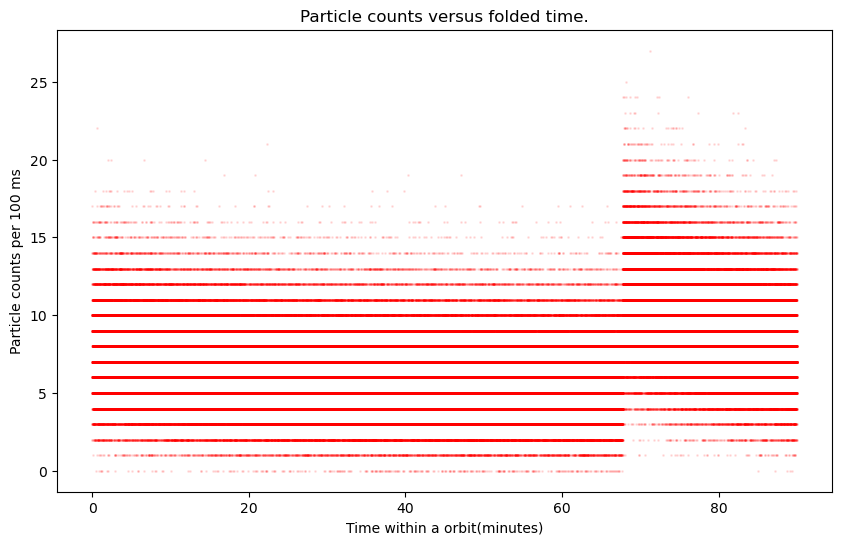

In [6]:
time = data[0,:]
solarPhase = data[1,:]
earthLongitude=data[2,:]
particleCounts=data[3,:]

x= time[0:216000] 
y= particleCounts [0:216000] 
#phase = np.mod(np.deg2rad(x), 2 * np.pi) 
#plt.figure(figsize=(10, 6))
#plt.scatter(phase, y, s=1, alpha=0.1, color='red') 
#plt.title("time vs particleCounts")  
#plt.xlim(0, 2 * np.pi)
#plt.grid(True, linestyle='--', alpha=0.6)  
#plt.show()  
phase = np.mod(x,5400) 
plt.figure(figsize=(10,6)) 
plt.scatter(phase /60, y, s=1, alpha=0.1, color="red")
plt.xlabel("Time within a orbit(minutes)") 
plt.ylabel("Particle counts per 100 ms") 
plt.title("Particle counts versus folded time.") 
plt.show()

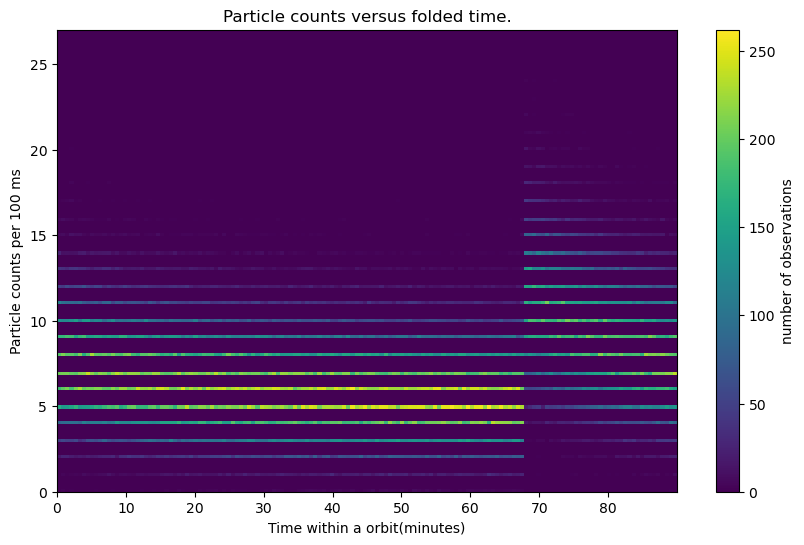

In [7]:
x= time[0:216000] 
y= particleCounts [0:216000] 
phase = np.mod(x,5400) 
plt.figure(figsize=(10,6)) 
plt.hist2d(phase /60, y, bins=150,cmap="viridis")
plt.colorbar(label="number of observations")
plt.xlabel("Time within a orbit(minutes)") 
plt.ylabel("Particle counts per 100 ms") 
plt.title("Particle counts versus folded time.") 
plt.show()

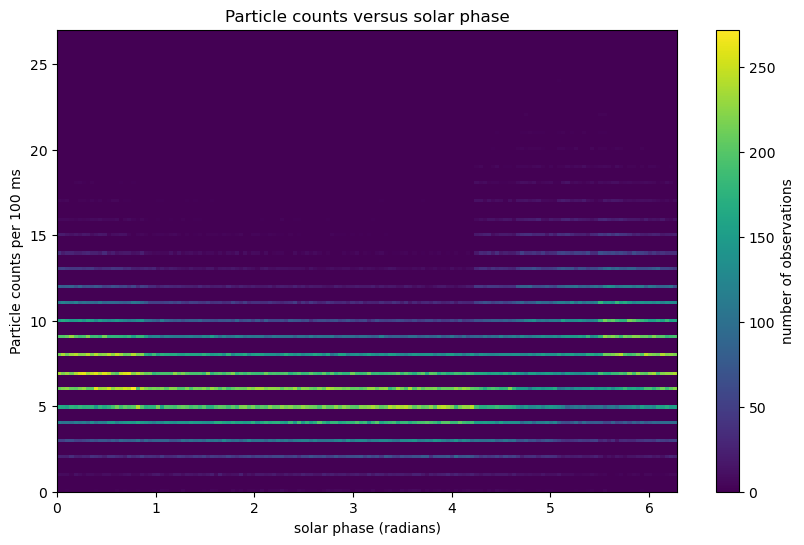

In [8]:
time = data[0,:]
solarPhase = data[1,:]
earthLongitude=data[2,:]
particleCounts=data[3,:]
x= solarPhase[0:216000] 
y= particleCounts [0:216000] 

phase = np.mod(np.deg2rad(x), 2 * np.pi) 
plt.figure(figsize=(10, 6))
plt.hist2d(phase, y, bins=150,cmap="viridis")
plt.colorbar(label="number of observations")
plt.xlabel("solar phase (radians)") 
plt.ylabel("Particle counts per 100 ms") 
plt.title("Particle counts versus solar phase")  
plt.xlim(0, 2 * np.pi)
plt.show() 

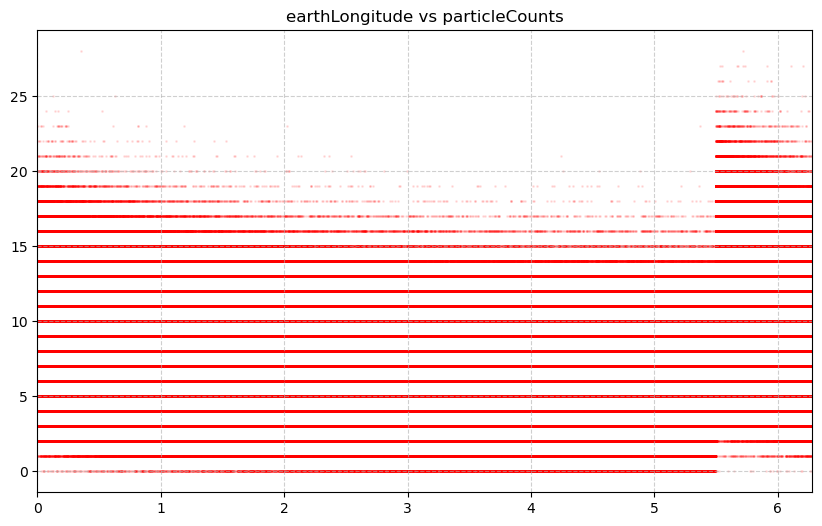

In [9]:
time = data[0,:]
solarPhase = data[1,:]
earthLongitude=data[2,:]
particleCounts=data[3,:]
x= earthLongitude[0:5500000] 
y= particleCounts[0:5500000] 

phase = np.mod(np.deg2rad(x), 2 * np.pi) 
plt.figure(figsize=(10, 6))
plt.scatter(phase, y, s=1, alpha=0.1, color='red') 
plt.title("earthLongitude vs particleCounts")  
plt.xlim(0, 2 * np.pi)
plt.grid(True, linestyle='--', alpha=0.6)  
plt.show() 

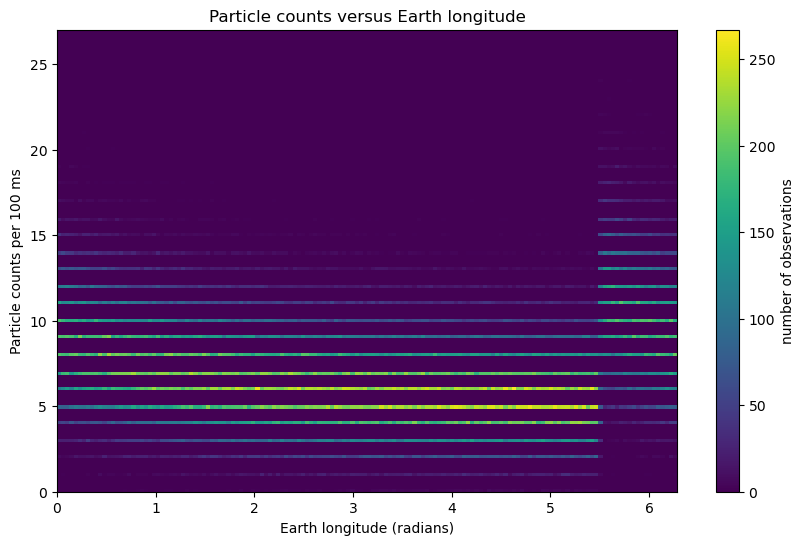

In [10]:
time = data[0,:]
solarPhase = data[1,:]
earthLongitude=data[2,:]
particleCounts=data[3,:]
x= earthLongitude[0:216000] 
y= particleCounts[0:216000] 

phase = np.mod(np.deg2rad(x), 2 * np.pi) 
plt.figure(figsize=(10, 6))
plt.hist2d(phase, y, bins=150,cmap="viridis")
plt.colorbar(label="number of observations")
plt.xlabel("Earth longitude (radians)") 
plt.ylabel("Particle counts per 100 ms") 
plt.title("Particle counts versus Earth longitude")  
plt.xlim(0, 2 * np.pi)
plt.show() 

Explaination: The count distribution change with orbital position. Higher counts become more common at certain portions of the cycle, meaning that the background is not constant. I did not see a clear burst in these plots, because the hist2d graph is mostly consistent it didn't have a sudden "bright" spot in those histograms. I plan to model background with a possion distribution whose mean changes over time. 

### Problem 2: 
The background is not consistent across the dataset. Find and describe as accurately as you can how the background changes.

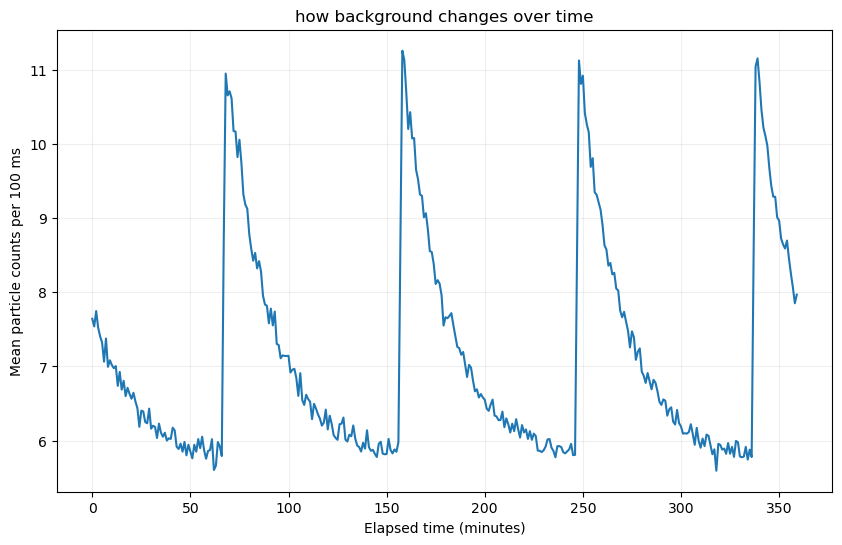

In [11]:
averageCount=[]
minutes =[]
for i in range(0,216000,600): 
    average=np.mean(particleCounts[i:i+600])
    averageCount.append(average)
    minute = (time[i] - time[0])/60
    minutes.append(minute)
plt.figure(figsize=(10, 6))
plt.plot (minutes, averageCount)
plt.xlabel("Elapsed time (minutes)") 
plt.ylabel("Mean particle counts per 100 ms") 
plt.title("how background changes over time")  
plt.grid(True, alpha =0.2)
plt.show()

For part 2 I find how background changes over time by plotting mean particles count per 100 ms versus Elapses time. This way instead of looking at a folded 2d histogram or scatter plot, the new graph above clearly shows the background changes over time. In the first approximately four orbits, the average rises shparly to around 11 counts per 100ms and then gradually decrease toward around 6 counts per 100ms. These same increases patterns occur around 68,158,250,and 340 minutes, which means that there is a repeating pattern in a period of around 90 minutes. 
This plot suggest that particles counts are more likely at some part of orbits than the other. using a simple Possion distribution with a constant mean would not desribe the overal interval well. This is because using one mean could underestimate the probability of high counts during higher background portions of the orbit, and it makes background fluctuations looks more significant than they actually are. Therefore, it is better to model a possion distribution whose mean changes with time.

### Problem 3:
Create a model for the background that includes time dependence, and explicitly compare your model to the data. How good is your model of the background?

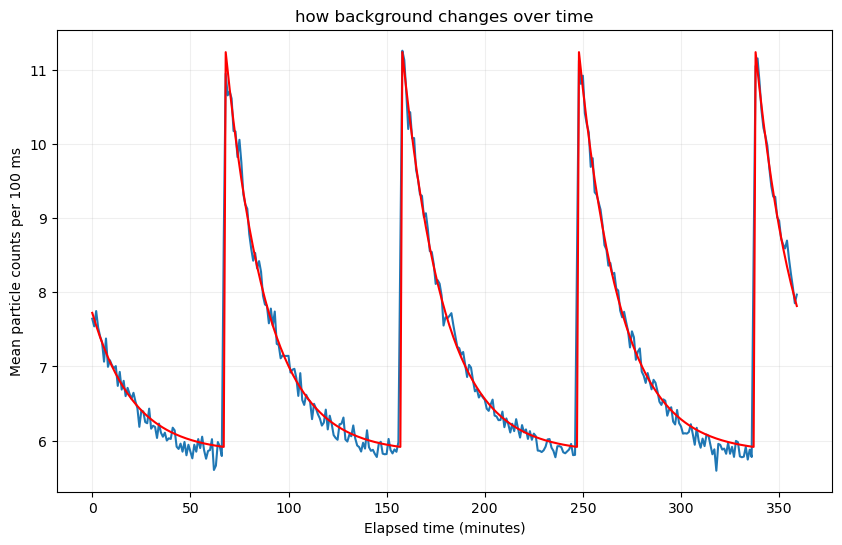

In [12]:
from scipy.optimize import curve_fit 
t = np.array(minutes)
y=np.array(averageCount)
def function(t,A,t2,c): 
    phase = np.mod(t-68,90)
    return c +A*np.exp(-phase/t2) 
parameters,_ = curve_fit(
    function,
    t,
    y,
    p0=[5,20,6],
) 
A = parameters[0]
t2 = parameters[1]
c = parameters[2]
model=function(t,A,t2,c) 
plt.figure(figsize=(10, 6))
plt.plot(t,y,label="Measured average")
plt.plot(t,model,color="red",label="model")
plt.xlabel("Elapsed time (minutes)") 
plt.ylabel("Mean particle counts per 100 ms") 
plt.title("how background changes over time")  
plt.grid(True, alpha =0.2)
plt.show()

I model the background with a Poisson distribution with a time dependent mean. I fit a reapting exponential decay, with parameters A describe amplitude of the expoential decay, t2 describing decay time, and c desribe the verticle baseline of the distribution. The model is a 90 minute period and the first rise  near 70 minutes are fixed from the graph.
From visual comparison, the fitted curve follows the sharp increase and graudually decrease pattern closely, although it is slightly above some of the lowestmeasured averages. Therefore, I think this model describe the changing mean well over first four orbits.

### Problem 4: 
Because the background varies, your discovery sensitivity threshold (how many particles you would need to see) also varies. What is the '5-sigma' threshold for a 100 millisecond GRB at different times?

[25. 25. 25. 25. 25. 24. 24. 24. 24. 24. 24. 24. 24. 23. 23. 23. 23. 23.
 23. 23. 23. 23. 23. 23. 23. 23. 23. 22. 22. 22. 22. 22. 22. 22. 22. 22.
 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22.
 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 32. 31. 31. 30.
 30. 30. 29. 29. 29. 28. 28. 28. 27. 27. 27. 27. 26. 26. 26. 26. 26. 25.
 25. 25. 25. 25. 25. 24. 24. 24. 24. 24. 24. 24. 24. 23. 23. 23. 23. 23.
 23. 23. 23. 23. 23. 23. 23. 23. 23. 22. 22. 22. 22. 22. 22. 22. 22. 22.
 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22.
 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 32. 31. 31. 30.
 30. 30. 29. 29. 29. 28. 28. 28. 27. 27. 27. 27. 26. 26. 26. 26. 26. 25.
 25. 25. 25. 25. 25. 24. 24. 24. 24. 24. 24. 24. 24. 23. 23. 23. 23. 23.
 23. 23. 23. 23. 23. 23. 23. 23. 23. 22. 22. 22. 22. 22. 22. 22. 22. 22.
 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22.
 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22. 22

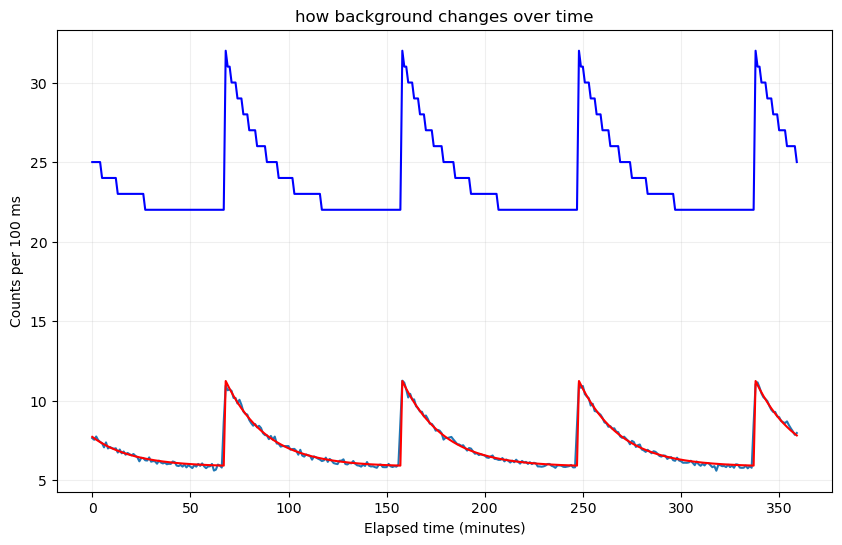

In [13]:
prob = stats.norm.cdf(5)
threshold = stats.poisson.ppf(prob, model)
print(threshold)

plt.figure(figsize=(10, 6))
plt.plot(t,y,label="Measured average")
plt.plot(t,model,color="red",label="model")
plt.plot(t,threshold,color = "blue",label = "threshold")
plt.xlabel("Elapsed time (minutes)") 
plt.ylabel("Counts per 100 ms") 
plt.title("how background changes over time")  
plt.grid(True, alpha =0.2)
plt.show()

I use stats.cdf(5) to compute the probability associated with 5 sigma. Then i use stats.poisson.ppf with the changing background mean from last part 3 to find the '5-sigma' threshold for a 100 millisecond GRB at different times. Lastly i graph the threshold versus time. The result suggest that the threshold increases when the higher-background portions of the orbit and decreases as the background fails, and the shape of the threshold vs time is consistent with the background plot. Therefore, more counts are needed to reach five sigma significance when the background is higher. The threhold applies to one 100ms observation at each time and the fitted Posson bakcground model desribe the data well. 

### Problem 5:
While this is simulated data, it is based on a real effect seen by low Earth orbit satellites. Can you identify the cause of the variable background and propose a physical model?

I propose that particles associated with cosmic rays or the sun could be the cause of changing background. When these particles hit the satellite, they can interact with materials in the detector, producing unstable radioactive nuclei. The nuclei then decay and emit radiation that adds to the detector counts. 
After strong explosure to space, the additional counts would initially be high and then decrease to a steady level as showing in my graph. Another exposure could increase the counts again. To explain the 90 minute repitation, I assume that the satellite might encouters a region of increased particle exposure at simular postion during those orbits. 